c:\Users\Schil\5.Semester\intelligence-engineering-5\.venv\Lib\site-packages\inference\core\env.py:345: InferenceDeprecationWarning: CORE_MODEL_GAZE_ENABLED is True: POST /gaze/gaze_detection is registered as a deprecation stub returning HTTP 410 Gone. The stub and this flag will be removed end of Q2 2026. Set CORE_MODEL_GAZE_ENABLED=False to disable it now.
  warnings.warn(
c:\Users\Schil\5.Semester\intelligence-engineering-5\.venv\Lib\site-packages\pydantic\_internal\_fields.py:198: UserWarning: Field name "schema" in "WorkflowsBlocksSchemaDescription" shadows an attribute in parent "BaseModel"
  warnings.warn(
c:\Users\Schil\5.Semester\intelligence-engineering-5\.venv\Lib\site-packages\onnxruntime\capi\onnxruntime_inference_collection.py:118: UserWarning: Specified provider 'CUDAExecutionProvider' is not in available provider names.Available providers: 'AzureExecutionProvider, CPUExecutionProvider'
  warnings.warn(
c:\Users\Schil\5.Semester\intelligence-engineering-5\.venv\Lib\site-

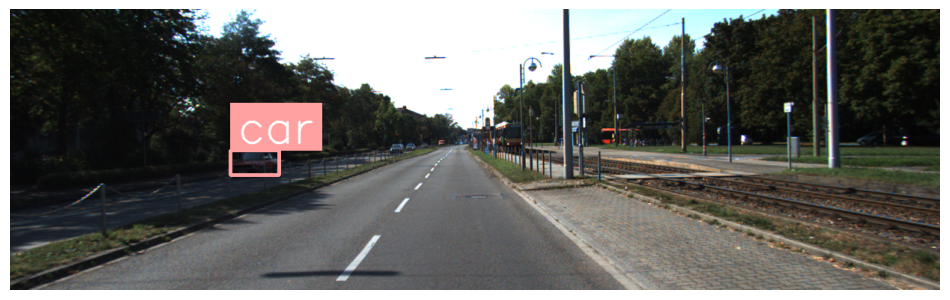

In [1]:
from inference import get_model
import supervision as sv
from inference.core.utils.image_utils import load_image_bgr
image = load_image_bgr("data/raw/testing/image_2/um_000001.png")
model = get_model(model_id="yolov8n-640")
results = model.infer(image)[0]
results = sv.Detections.from_inference(results)
annotator = sv.BoxAnnotator(thickness=4)
annotated_image = annotator.annotate(image, results)
annotator = sv.LabelAnnotator(text_scale=2, text_thickness=2)
annotated_image = annotator.annotate(annotated_image, results)
sv.plot_image(annotated_image)

In [2]:
import time
import statistics

# Einstellungen
warmup_runs = 5
measurement_runs = 30

# 1. Aufwärmen – diese Durchläufe werden nicht gemessen
for _ in range(warmup_runs):
    model.infer(image)

# 2. Einzelbild-Latenz messen
latencies = []

for _ in range(measurement_runs):
    start_time = time.perf_counter()

    model.infer(image)

    end_time = time.perf_counter()
    latency_ms = (end_time - start_time) * 1000

    latencies.append(latency_ms)

# 3. Ergebnisse berechnen
sorted_latencies = sorted(latencies)

print(f"Anzahl Messungen: {measurement_runs}")
print(f"Durchschnitt:     {statistics.mean(latencies):.2f} ms")
print(f"Median:           {statistics.median(latencies):.2f} ms")
print(f"Minimum:          {min(latencies):.2f} ms")
print(f"Maximum:          {max(latencies):.2f} ms")
print(f"95. Perzentil:    {sorted_latencies[int(0.95 * (len(sorted_latencies)-1))]:.2f} ms")

Anzahl Messungen: 30
Durchschnitt:     89.59 ms
Median:           83.09 ms
Minimum:          73.12 ms
Maximum:          205.69 ms
95. Perzentil:    94.83 ms


In [ ]:
import time
import statistics

# Einstellungen
warmup_runs = 5
measurement_runs = 30

# 1. Aufwärmen – diese Durchläufe werden nicht gemessen
for _ in range(warmup_runs):
    model.infer(image)

# 2. Einzelbild-Latenz messen
latencies = []

for _ in range(measurement_runs):
    start_time = time.perf_counter()

    model.infer(image)

    end_time = time.perf_counter()
    latency_ms = (end_time - start_time) * 1000

    latencies.append(latency_ms)

# 3. Ergebnisse berechnen
sorted_latencies = sorted(latencies)

print(f"Anzahl Messungen: {measurement_runs}")
print(f"Durchschnitt:     {statistics.mean(latencies):.2f} ms")
print(f"Median:           {statistics.median(latencies):.2f} ms")
print(f"Minimum:          {min(latencies):.2f} ms")
print(f"Maximum:          {max(latencies):.2f} ms")
print(f"95. Perzentil:    {sorted_latencies[int(0.95 * (len(sorted_latencies)-1))]:.2f} ms")

Anzahl Messungen: 30
Durchschnitt:     89.59 ms
Median:           83.09 ms
Minimum:          73.12 ms
Maximum:          205.69 ms
95. Perzentil:    94.83 ms


In [3]:
from pathlib import Path
from inference.core.utils.image_utils import load_image_bgr
import time
import statistics

# Einstellungen
batch_size = 16
batch_runs = 5
warmup_runs = 5

# 1. Bilder auswählen
image_dir = Path("data/raw/testing/image_2")

image_paths = sorted([
    p for p in image_dir.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
])[:batch_size]

if len(image_paths) < batch_size:
    raise ValueError("Nicht genügend Bilder im Testdatensatz gefunden.")

# 2. Bilder vorab laden (nicht Teil der Messung)
batch_images = [
    load_image_bgr(str(path))
    for path in image_paths
]

print(f"Batchgröße: {len(batch_images)} Bilder")

# 3. Aufwärmen
for img in batch_images[:warmup_runs]:
    model.infer(img)

# 4. Batch-Durchsatz messen
batch_times = []

for _ in range(batch_runs):
    start_time = time.perf_counter()

    for img in batch_images:
        model.infer(img)

    end_time = time.perf_counter()

    batch_times.append(end_time - start_time)

# 5. Ergebnisse berechnen
total_time = sum(batch_times)
total_images = batch_size * batch_runs

throughput = total_images / total_time
average_batch_time = statistics.mean(batch_times)
average_image_time = average_batch_time / batch_size * 1000

print("\n--- Batch-Throughput ---")
print(f"Batchgröße:              {batch_size} Bilder")
print(f"Anzahl Batch-Durchläufe: {batch_runs}")
print(f"Verarbeitete Bilder:     {total_images}")
print(f"Durchschnittliche Batch-Zeit: {average_batch_time:.3f} Sekunden")
print(f"Durchschnittliche Zeit pro Bild: {average_image_time:.2f} ms")
print(f"Gesamtdurchsatz:         {throughput:.2f} Bilder/Sekunde")

Batchgröße: 16 Bilder

--- Batch-Throughput ---
Batchgröße:              16 Bilder
Anzahl Batch-Durchläufe: 5
Verarbeitete Bilder:     80
Durchschnittliche Batch-Zeit: 1.453 Sekunden
Durchschnittliche Zeit pro Bild: 90.80 ms
Gesamtdurchsatz:         11.01 Bilder/Sekunde
